# GCN models
- Visualise data and chose thresholds
- Prepare data
- Train classification model
- Predict and evaluate classification model
- Prepare data for regression model
- Train regression model
- Predict and evaluate regression model

In [74]:
# Avoid rerunning - set random seed:
import random
random.seed(10)

import pandas as pd
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve
from sklearn.model_selection import train_test_split
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.metrics as met
from sklearn.metrics import confusion_matrix
#plt.style.use('seaborn')
plt.rcParams['font.size'] = 12
from aux_functions import *

### 1. Import input data

Laget i `create_dataset.py`-fil.

In [75]:
df = pd.read_csv(r'./data/tot_cost_failure_scenarios_300322.csv')

###  2. Visualiser data

#### Histogram

Histogram has a gap around 1.3 and 1.8 p.u. We use the first gap for distinguising between low and high cost for the classification. Despite this gap, the classification model is expected to falsely classify some of the nearby points as low cost, so we train the regression model including some of those points.

In [76]:
class_thresh = 1.3
clamp_thresh = 1.45

df["Class"] = df.apply(lambda row: 0.0 if row["Total cost"] < class_thresh else 1.0, axis=1) # Should be just done with index rather than apply

In [77]:
high_cost_corrective = df.loc[df["Class"] == 1, 'Correction cost'].median()
high_cost_corrective # Used later as value for high cost scenarios

8.187550678436416

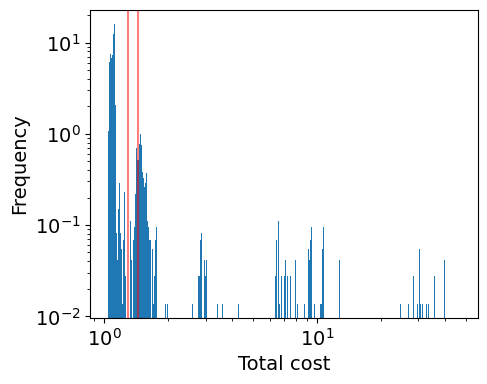

In [78]:
#plt.style.use('seaborn-colorblind')
#plt.style.use('default')

fig, ax = plt.subplots(figsize=(5, 4))
#ax.set_ylim([0,1.1])
#ax.set_xlim([1,3])
ax.set_yscale('log')
ax.set_xscale('log')
ax = setfontsize(ax, 14)
df["Total cost"].plot.hist(bins=5000, ax=ax, density=True, xlabel='Total cost (p.u.)')
ax.set_xlabel('Total cost')
ax.axvline(class_thresh, color='red', alpha=0.5)
ax.axvline(clamp_thresh, color='red', alpha=0.5)
plt.savefig('./paper_figs/hist.pdf', bbox_inches='tight')

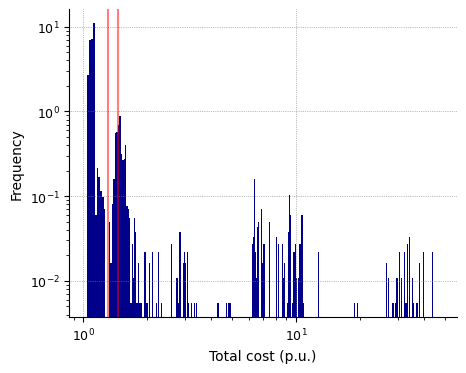

In [79]:
plt.style.use('default')
fig, ax = plt.subplots(figsize=(5, 4))
#ax.set_ylim([0,1.1])
#ax.set_xlim([1,3])
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.set_yscale('log')
ax.set_xscale('log')
ax = setfontsize(ax, 14)
df["Total cost"].plot.hist(bins=2000, color = 'darkblue', ax=ax, density=True, xlabel='Total cost (p.u.)')
ax.axvline(class_thresh, color='red', alpha=0.5)
ax.axvline(clamp_thresh, color='red', alpha=0.5)
ax.grid(linestyle=':', linewidth='0.5', color='grey')
# Set the tick labels font
for label in (ax.get_xticklabels() + ax.get_yticklabels()):
    #label.set_fontname('Arial')
    label.set_fontsize(9)
# Set the axisfont
axis_font = {'size':'10'}
ax.set_xlabel('Total cost (p.u.)', **axis_font)
ax.set_ylabel('Frequency', **axis_font)
plt.savefig('./paper_figs/hist_new.pdf', bbox_inches='tight')

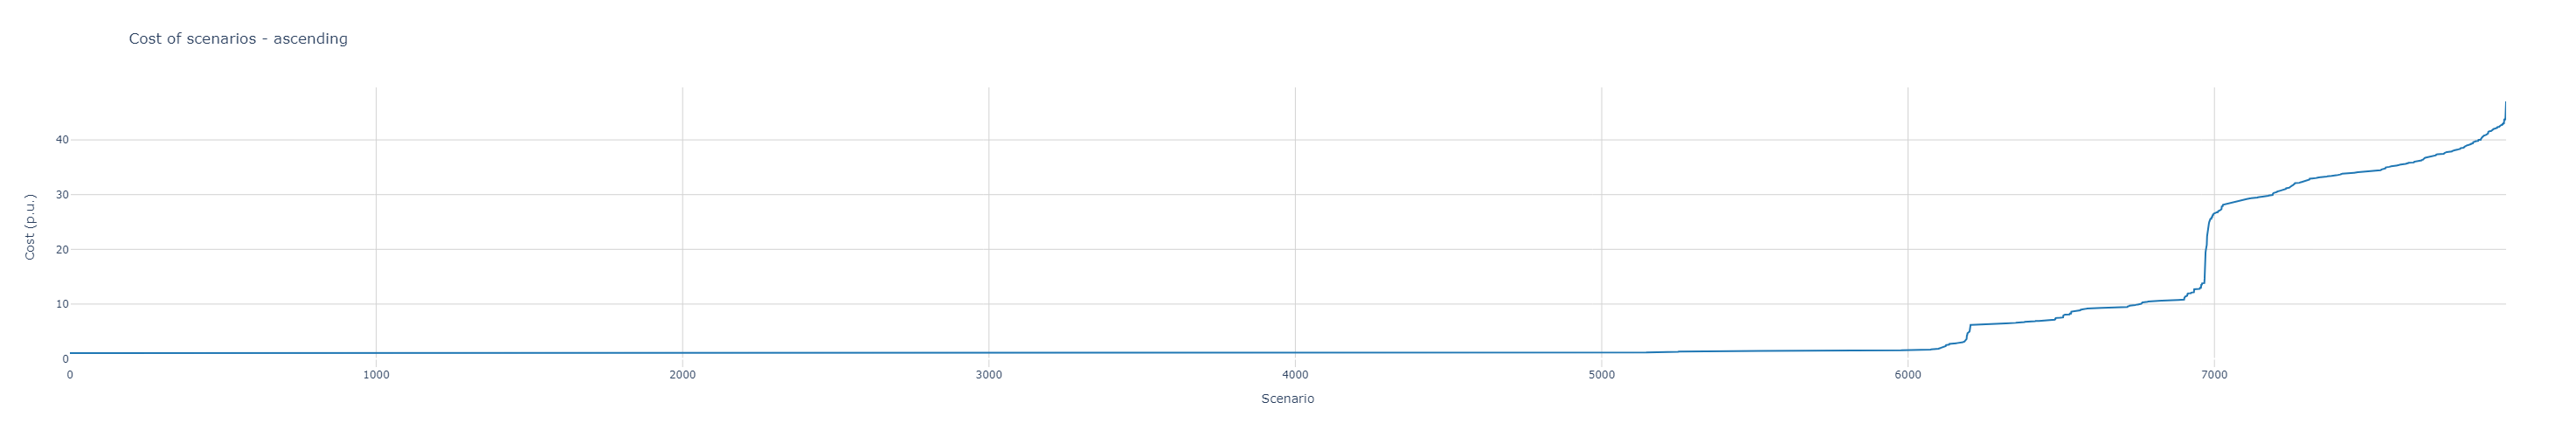

In [80]:
plot_df = df.sort_values(by=['Total cost'])
x_values = np.arange(plot_df.shape[0])

layout = go.Layout(
    title = f'Cost of scenarios - ascending',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

fig.add_trace(go.Scatter(x=x_values, y=plot_df['Total cost'], mode='lines', line=dict(color='#1F77B4'), name="True"))

fig.update_layout(
    xaxis_title='Scenario',
    yaxis_title='Cost (p.u.)',
    width=700, height=500
)
fig.show()

#### Correlation plot

Check if any features correlate strongly with output of classification model

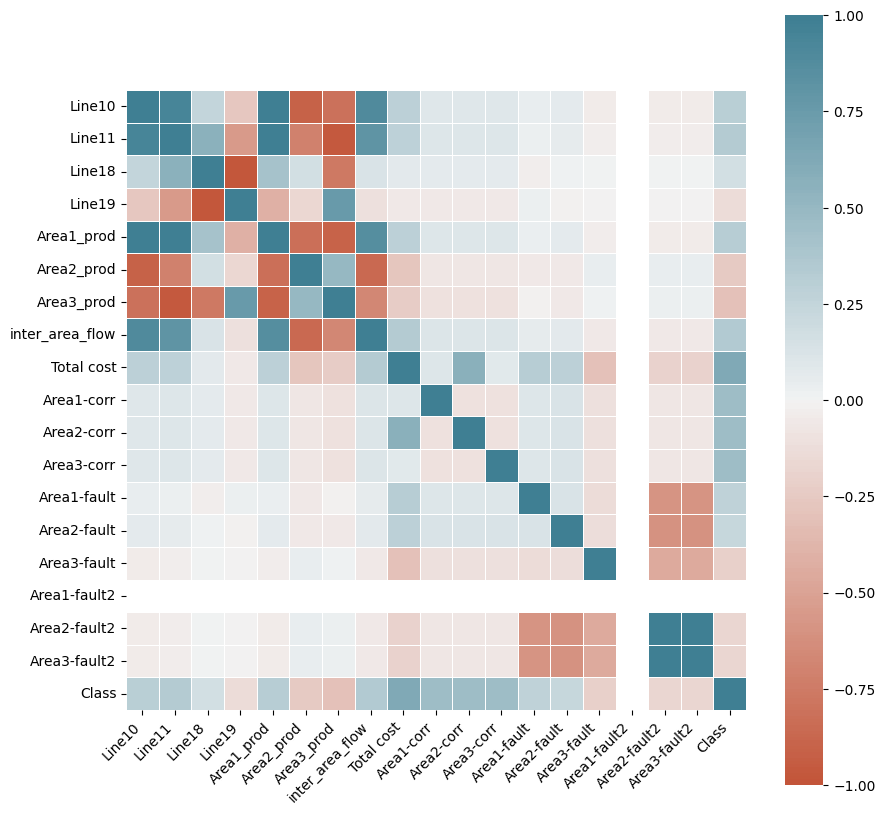

In [81]:
plot_var = ['prev_id', 'Line10', 'Line11', 'Line18', 'Line19', 'Area1_prod', 'Area2_prod', 'Area3_prod', 'inter_area_flow', 'fault', 'corr', 
          'Total cost', 'Area1-corr', 'Area2-corr', 'Area3-corr', 'Area1-fault', 'Area2-fault', 'Area3-fault', 'Area1-fault2', 'Area2-fault2', 'Area3-fault2', 'Class']


corr = df[plot_var].corr()
fig, ax = plt.subplots(figsize=(10,10))  
ax = sns.heatmap(
    corr, 
    vmin=-1, vmax=1, center=0,
    cmap=sns.diverging_palette(20, 220, n=200),
    square=True, linewidths=.5
)
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    horizontalalignment='right'
);

## 4. Prepare data for classification
train_test_split splits data into train and test while also shuffling. Train 70%, validation 10%, test 20%
random_state chooses seed for shuffling which gives more consistency for our process.

Test dataset need to be large since this is what is used in regression model.

Splitting into train and test set while keeping all scenarios with the same prev_id in the same set.

In [82]:
prev_ids = df.prev_id.unique()
grouped = df.groupby(df.prev_id)

df_list = []
for prev_id in prev_ids:
    df_list.append(grouped.get_group(prev_id))


train_df_list, test_val_df_list = train_test_split(
    df_list, test_size=0.3, random_state=1
)
val_df_list, test_df_list = train_test_split(
    test_val_df_list, test_size=1 / 3, random_state=1
)

train_df = pd.concat(train_df_list)
val_df = pd.concat(val_df_list)
test_df = pd.concat(test_df_list)

### 4.Train classification model

In [114]:
is_tuning = False # True for hyper parameter optimization
%run -i "gcn_classification.py"

C:\Users\erlendk\base\lib\site-packages\torch_geometric\deprecation.py:12: UserWarning:

'data.DataLoader' is deprecated, use 'loader.DataLoader' instead

C:\Users\erlendk\base\lib\site-packages\torch_geometric\deprecation.py:12: UserWarning:

'data.DataLoader' is deprecated, use 'loader.DataLoader' instead

C:\Users\erlendk\base\lib\site-packages\torch_geometric\deprecation.py:12: UserWarning:

'data.DataLoader' is deprecated, use 'loader.DataLoader' instead



Number of training graphs: 5567
Number of validation graphs: 1537
Number of test graphs: 849
Epoch: 001, Train Acc: 0.8064, Validation Acc: 0.8100
Epoch: 002, Train Acc: 0.9335, Validation Acc: 0.9382
Epoch: 003, Train Acc: 0.9578, Validation Acc: 0.9623
Epoch: 004, Train Acc: 0.9677, Validation Acc: 0.9681
Epoch: 005, Train Acc: 0.9639, Validation Acc: 0.9655
Epoch: 006, Train Acc: 0.9705, Validation Acc: 0.9727
Epoch: 007, Train Acc: 0.9705, Validation Acc: 0.9714
Epoch: 008, Train Acc: 0.9702, Validation Acc: 0.9720
Epoch: 009, Train Acc: 0.9705, Validation Acc: 0.9727
Epoch: 010, Train Acc: 0.9709, Validation Acc: 0.9733
Epoch: 011, Train Acc: 0.9702, Validation Acc: 0.9720
Epoch: 012, Train Acc: 0.9616, Validation Acc: 0.9636
Epoch: 013, Train Acc: 0.9732, Validation Acc: 0.9772
Epoch: 014, Train Acc: 0.9707, Validation Acc: 0.9733
Epoch: 015, Train Acc: 0.9736, Validation Acc: 0.9785
Epoch: 016, Train Acc: 0.9731, Validation Acc: 0.9772
Epoch: 017, Train Acc: 0.9702, Validation A

In [115]:
#output from hyperparameter run
#0.9908913467794405
#4
#The lowest total MSE value, 0.9908913, for the validation set was found with the following settings: 
#a learning rate of: 0.0009, a hidden channel nr of: 29.0
#a dropout rate of: 0.1000 and an epoch number of: 40.0

In [116]:
classification_model = model
classification_test_dataset = test_dataset

In [117]:
model

GCN(
  (conv1): GCNConv(5, 12)
  (conv2): GCNConv(12, 12)
  (conv3): GCNConv(12, 12)
  (lin): Linear(in_features=12, out_features=1, bias=True)
)

### 5. Output of classification model

#### Convergence plot

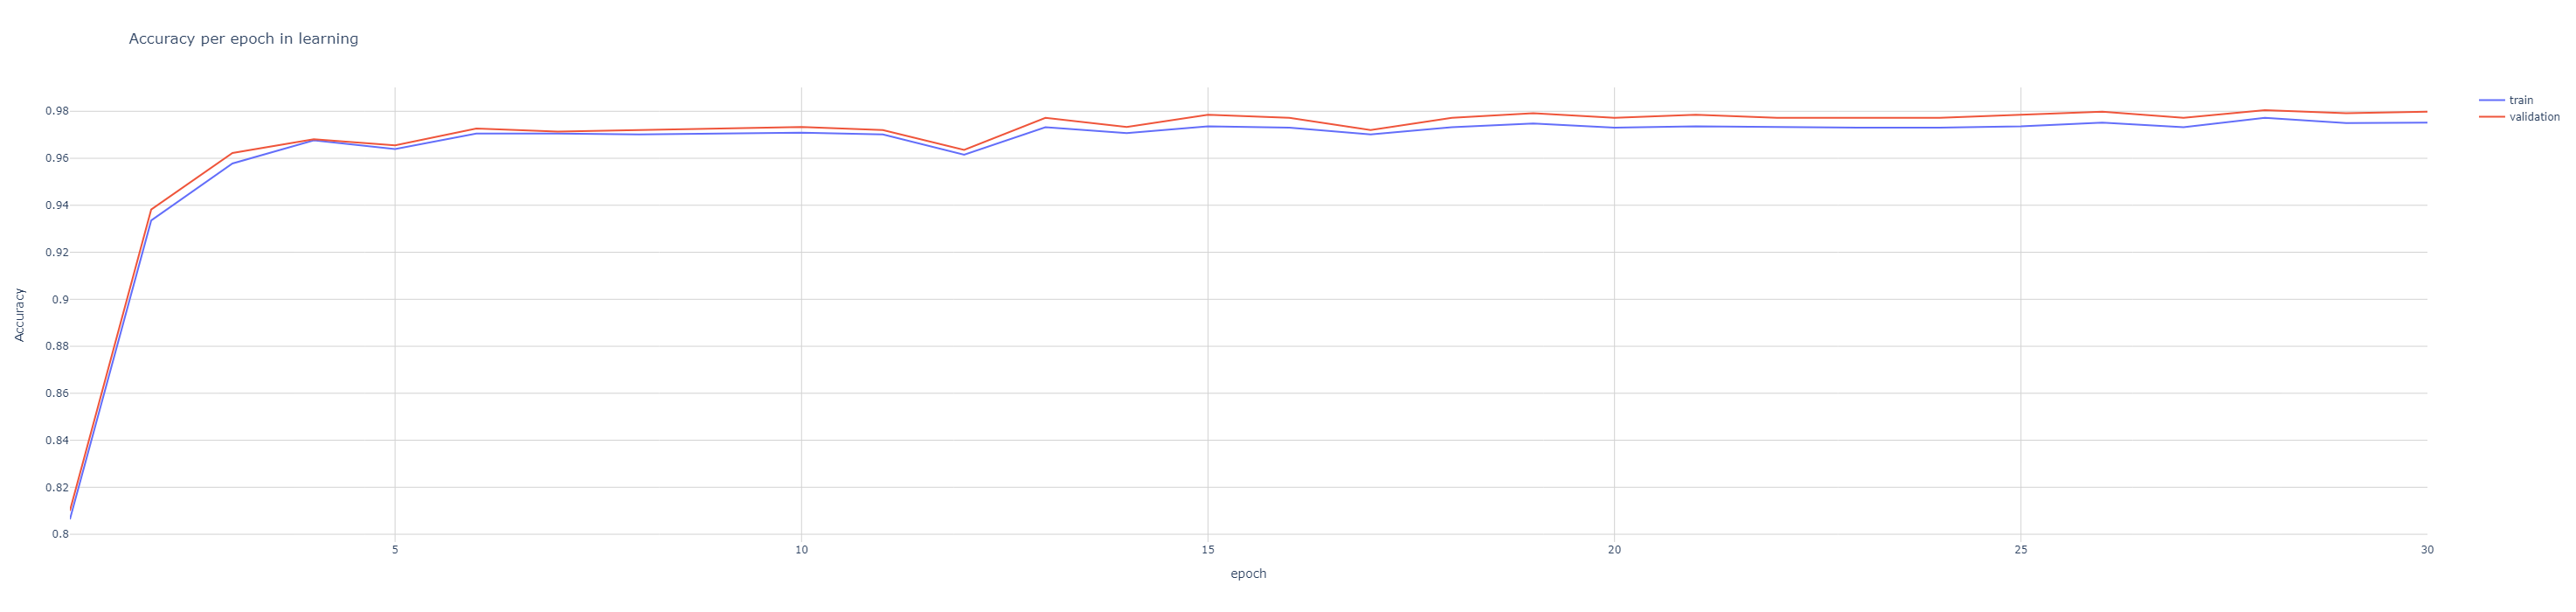

In [118]:
epoch_list = np.arange(1, len(train_list)+1)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=epoch_list,
    y=train_list,
    name="train"       # this sets its legend entry
))


fig.add_trace(go.Scatter(
    x=epoch_list,
    y=val_list,
    name="validation"       # this sets its legend entry
))

fig.update_layout(
    title="Accuracy per epoch in learning",
    xaxis_title="epoch",
    yaxis_title="MSE",
     xaxis = dict(
        title = 'epoch',
        gridcolor='lightgrey'),
    yaxis = dict(
        title = 'Accuracy',
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)',
    width=1000,
    height=700
)

fig.show()

### Classification results from test data

#### Precision-recall curve

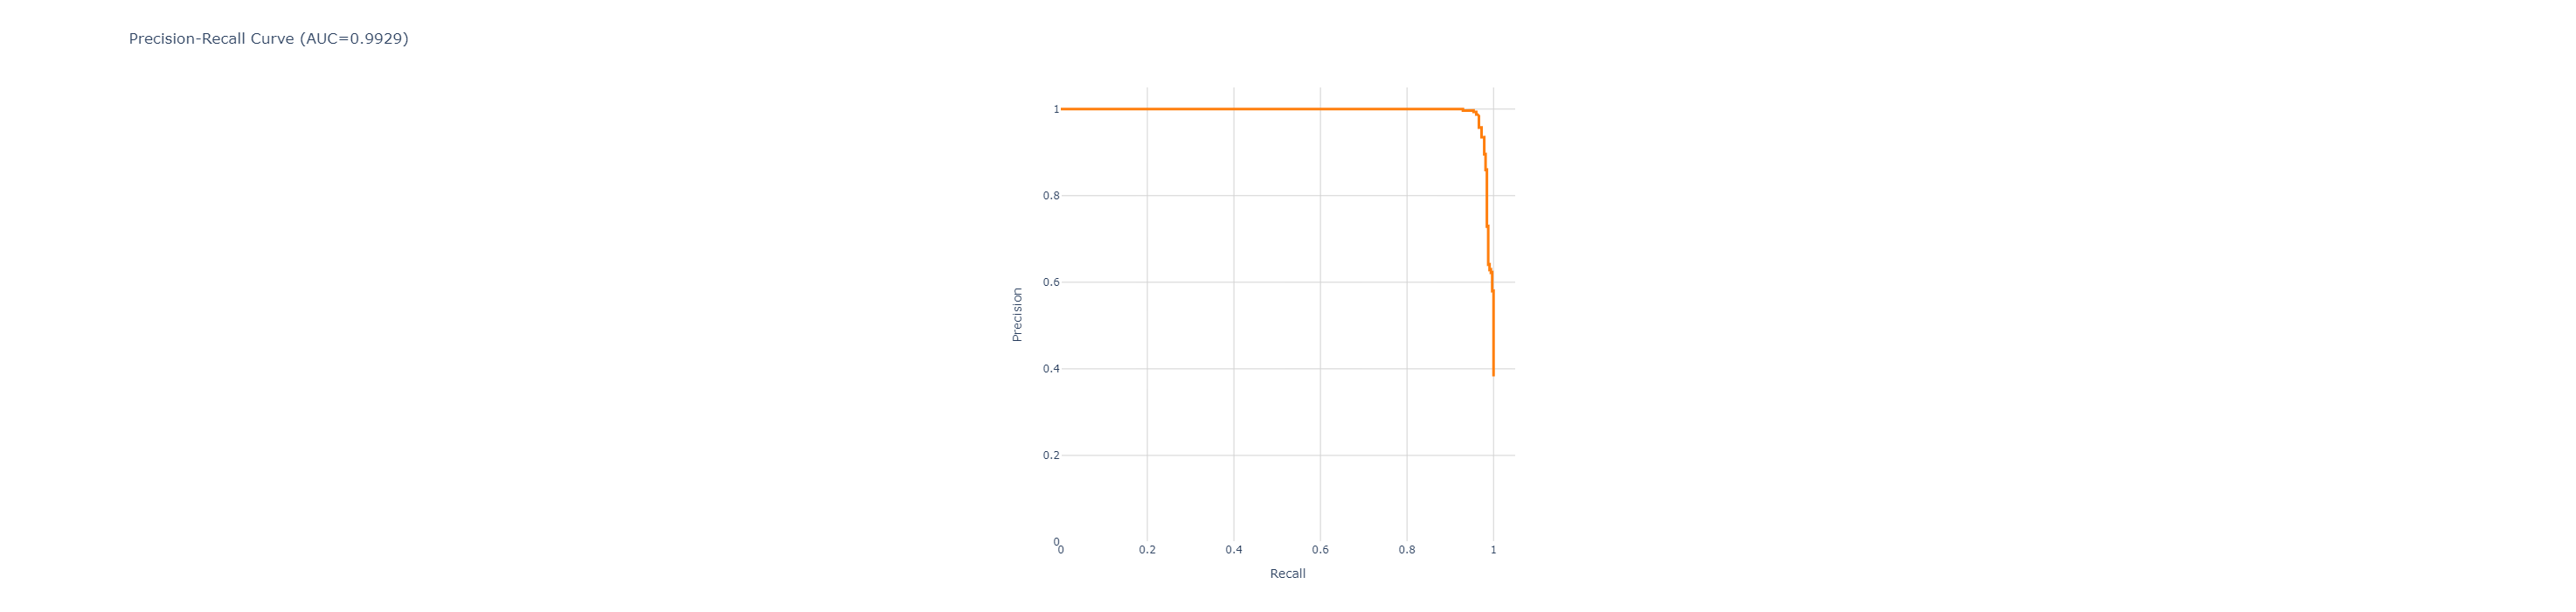

In [119]:
precision, recall, thresholds = precision_recall_curve(y_target, y_prob)

df_ = pd.DataFrame(data={"precision": precision, "recall": recall, "thresh":np.append(0, thresholds)})

layout = go.Layout(
    title = f'Precision-Recall Curve (AUC={auc(recall, precision):.4f})',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)
#fig.add_shape(
#    type='line', line=dict(dash='dash'),
#    x0=0, x1=1, y0=0.577, y1=0.577, name= "Baseline"
#)


fig.add_trace(go.Scatter(x=df_['recall'], y=df_['precision'], mode='lines', line=dict(color='#FF7F0E', width=3), name="curve",))

fig.update_layout(
    xaxis_title='Recall',
    yaxis_title='Precision',
    yaxis=dict(scaleanchor="x", scaleratio=1, range=[0,1.05]),
    xaxis=dict(constrain='domain', range=[0,1.05]),
    width=700, height=700
)
fig.show()
#fig, ax = plt.subplots()
#ax = setfontsize(ax, 18)
#ax.set_ylim([0, 1.1])
#ax.set_xlim([0, 1.1])
#ax.plot(df_['recall'], df_['precision'])
#ax.set_xlabel('Recall')
#ax.set_ylabel('Precision')

#plt.savefig('hist.png')

#### Threshold probability

The classification threshold probability is selected to provide the highest F2 value for the trained model.

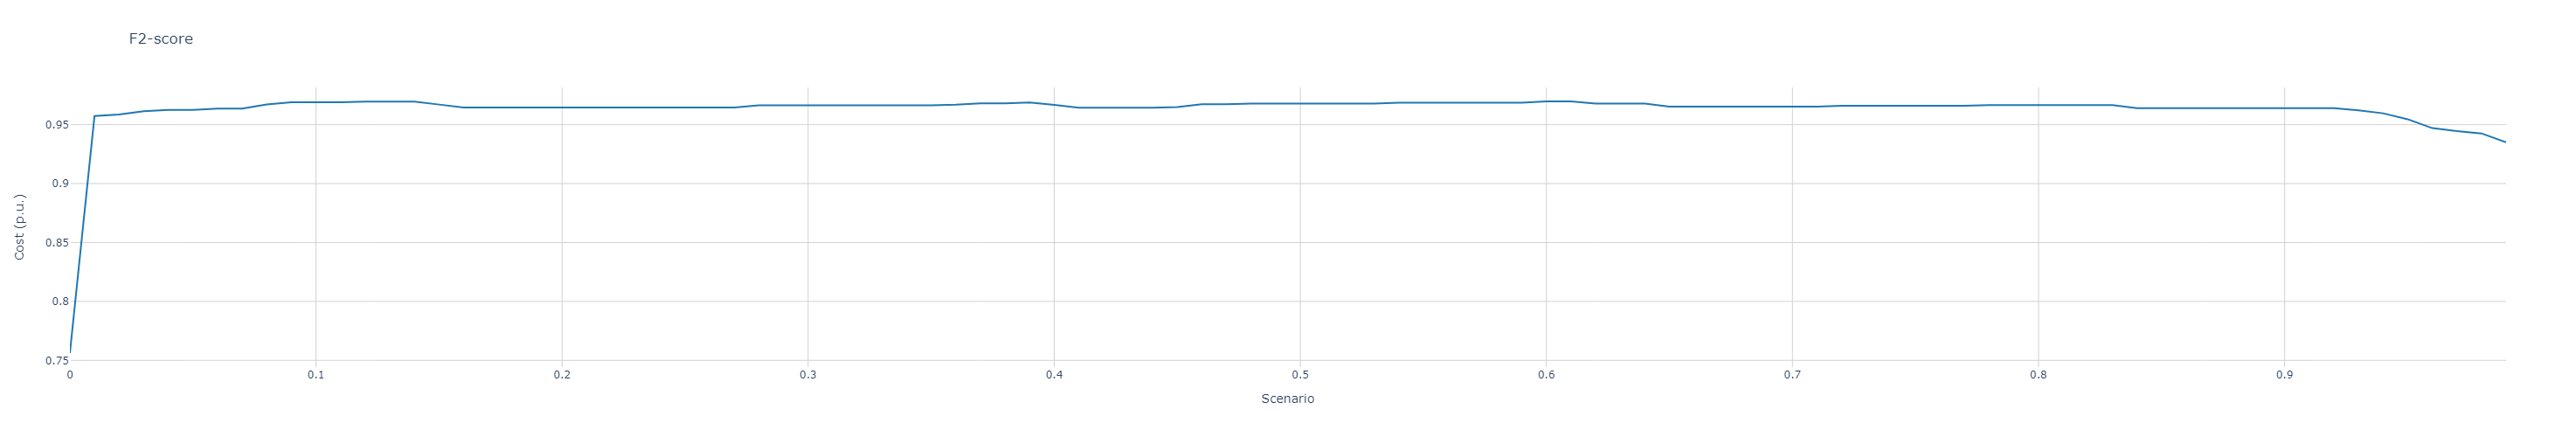

In [120]:
from sklearn.metrics import fbeta_score

t_prob = np.arange(0,1, 0.01)
f2_score = np.array([])

for thresh in t_prob:
    pred = np.array([1 if x > thresh else 0 for x in y_prob])
    f2_score = np.append(f2_score, fbeta_score(y_target, pred, beta=2))
    
layout = go.Layout(
    title = f'F2-score',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

fig.add_trace(go.Scatter(x=t_prob, y=f2_score, mode='lines', line=dict(color='#1F77B4'), name="True"))

fig.update_layout(
    xaxis_title='Scenario',
    yaxis_title='Cost (p.u.)',
    width=700, height=500
)
fig.show()

In [121]:
# Finn threshold som gir max f2-score
df_ = pd.DataFrame(data={"f2": f2_score, "thresh": t_prob})
th_p = df_['thresh'][df_['f2']==df_['f2'].max()].values[0]
th_p

0.6

In [122]:
# Bruk threshold for å klassifisere på nytt
y_pred_f2 = np.array([1 if x > th_p else 0 for x in y_prob])
y_pred = np.array([1 if x > 0.5 else 0 for x in y_prob])
acc = (y_target == y_pred_f2).sum()/len(y_target)
acc

0.9811542991755006

In [123]:
df_results['pred_f2'] = y_pred_f2
df_results['pred'] = y_pred

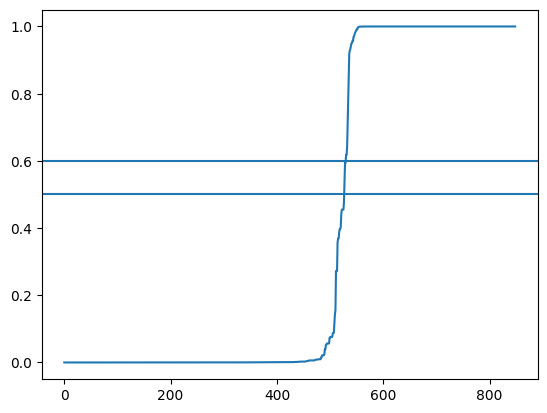

In [124]:
plt.plot(np.sort(y_prob))
plt.axhline(th_p)
plt.axhline(0.5)

#### Confusion matrix

In [125]:
tn, fp, fn, tp = confusion_matrix(y_target, y_pred_f2).ravel()
(tn, fp, fn, tp)

(519, 5, 11, 314)

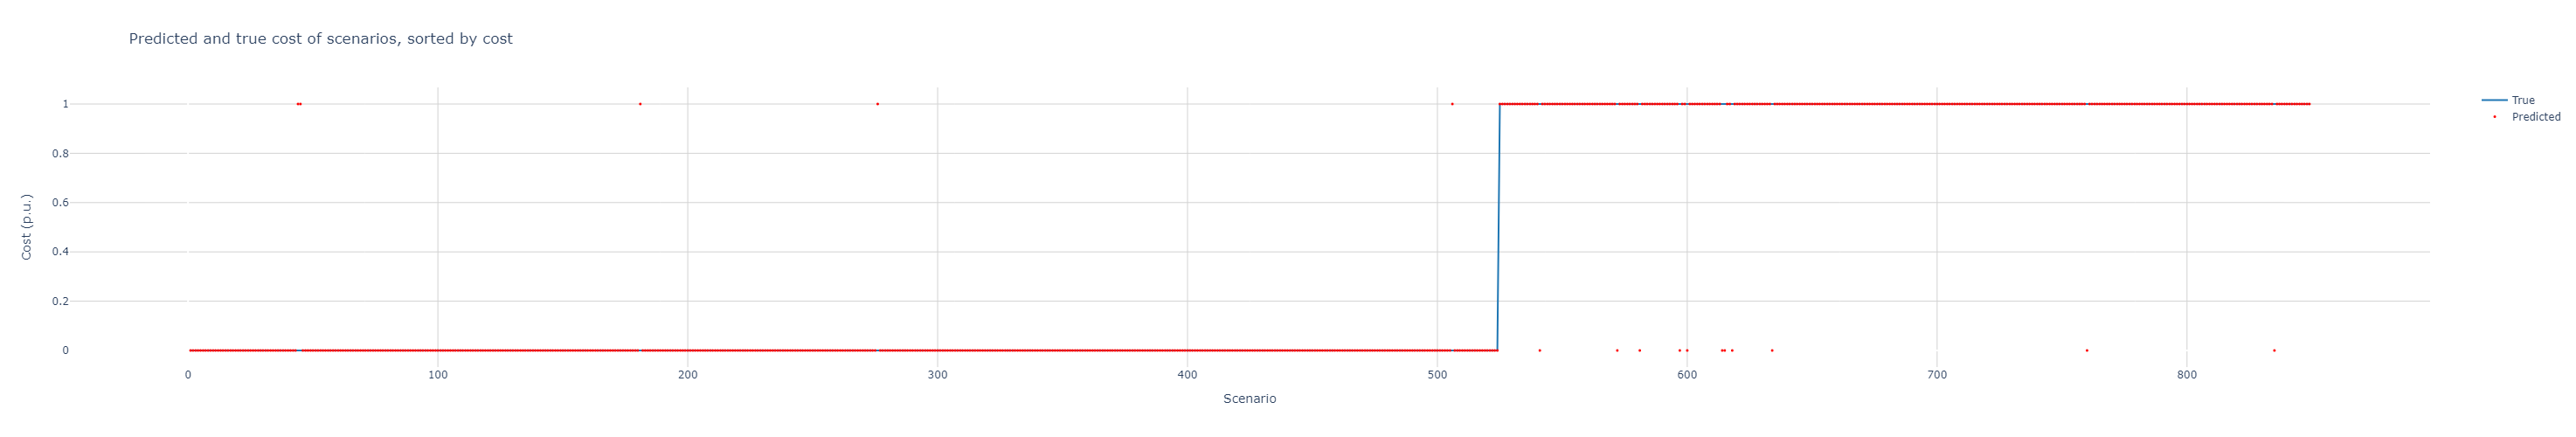

In [126]:
plot_df = df_results.sort_values(by=['target'])

layout = go.Layout(
    title = f'Predicted and true cost of scenarios, sorted by cost',
    xaxis = dict(
        gridcolor='lightgrey'),
    yaxis = dict(
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)'
)

fig = go.Figure(layout=layout)

fig.add_trace(go.Scatter(x=x_values, y=plot_df['target'], mode='lines', line=dict(color='#1F77B4'), name="True"))
fig.add_trace(go.Scatter(x=x_values, y=plot_df['pred_f2'], mode='markers', marker=dict(color='red', size=3), name="Predicted"))

fig.update_layout(
    xaxis_title='Scenario',
    yaxis_title='Cost (p.u.)',
    width=700, height=500
)
fig.show()

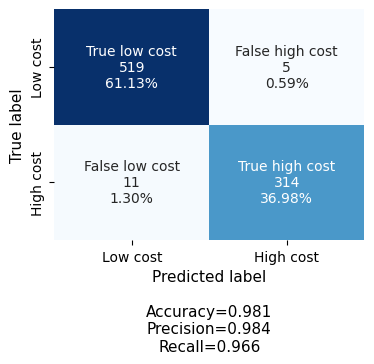

In [127]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def make_confusion_matrix_new(cf,
                          group_names=None,
                          categories='auto',
                          count=True,
                          percent=True,
                          cbar=True,
                          xyticks=True,
                          xyplotlabels=True,
                          sum_stats=True,
                          figsize=None,
                          cmap='Blues',
                          title=None):

    blanks = ['' for i in range(cf.size)]

    if group_names and len(group_names)==cf.size:
        group_labels = ["{}\n".format(value) for value in group_names]
    else:
        group_labels = blanks

    if count:
        group_counts = ["{0:0.0f}\n".format(value) for value in cf.flatten()]
    else:
        group_counts = blanks

    if percent:
        group_percentages = ["{0:.2%}".format(value) for value in cf.flatten()/np.sum(cf)]
    else:
        group_percentages = blanks

    box_labels = [f"{v1}{v2}{v3}".strip() for v1, v2, v3 in zip(group_labels,group_counts,group_percentages)]
    box_labels = np.asarray(box_labels).reshape(cf.shape[0],cf.shape[1])


    # CODE TO GENERATE SUMMARY STATISTICS & TEXT FOR SUMMARY STATS
    if sum_stats:
        #Accuracy is sum of diagonal divided by total observations
        accuracy  = np.trace(cf) / float(np.sum(cf))
        if len(cf)==2:
            #Metrics for Binary Confusion Matrices
            precision = cf[1,1] / sum(cf[:,1])
            recall    = cf[1,1] / sum(cf[1,:])
            f1_score  = 2*precision*recall / (precision + recall)
            stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}".format(
                accuracy,precision,recall)
            #stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
            #    accuracy,precision,recall,f1_score)
        else:
            stats_text = "\n\nAccuracy={:0.3f}".format(accuracy)
    else:
        stats_text = ""

    if figsize==None:
        figsize = plt.rcParams.get('figure.figsize')

    if xyticks==False:
        categories=False

    plt.figure(figsize=figsize)
    sns.heatmap(cf,annot=box_labels,fmt="",cmap=cmap,cbar=cbar,xticklabels=categories,yticklabels=categories, annot_kws={"size": 10})

    if xyplotlabels:
        plt.ylabel('True label', fontsize=11)
        plt.xlabel('Predicted label' + stats_text, fontsize=11)
    else:
        plt.xlabel(stats_text, fontsize=10)
    
    if title:
        plt.title(title, fontsize=10)
    
    plt.yticks(fontsize=10)
    plt.xticks(fontsize=10)

    
cf_matrix = confusion_matrix(df_results['target'], df_results['pred_f2'])

labels = ['True low cost','False high cost','False low cost','True high cost']
categories = ['Low cost', 'High cost']
make_confusion_matrix_new(cf_matrix, 
                      group_names=labels,
                      categories=categories, 
                      cmap='Blues',
                      title='',
                      cbar=False,
                      figsize=(4, 3)
                     )

plt.savefig("./paper_figs/confusion_matrix_new.pdf", bbox_inches='tight')


In [128]:
df_results['target']

5787    0.0
5788    0.0
5789    0.0
5790    0.0
7778    0.0
       ... 
3330    0.0
252     0.0
253     0.0
254     0.0
255     0.0
Name: target, Length: 849, dtype: float64

In [98]:
index_wrongclass = (df_results.target - df_results.pred_f2).abs() > 0
df_results.loc[index_wrongclass, ['Total cost', 'Dispatch costs', 'Correction cost']]

,Total cost,Dispatch costs,Correction cost
5787,1.066870,1.038699,0.028171
7520,1.068075,1.036421,0.031654
7521,1.187342,1.036421,0.150920
7526,10.261521,1.036421,9.225100
506,1.065285,1.038657,0.026628
1447,1.072238,1.046432,0.025806
5431,1.205251,1.023266,0.181985
408,1.072238,1.046432,0.025806
463,1.126128,1.031004,0.095125
7352,1.065285,1.038657,0.026628


### 6. Export classification results to csv

In [39]:
# Bruk kun scenarier som er klassifisert som lavkostnads med ny terskel

#df = df_results[df_results['pred_f2']==0][['prev_id', 'Line10', 'Line11', 'Line18', 'Line19', 'Area1_prod', 'Area2_prod', 'Area3_prod', 'Area1_load', 'Area2_load', 'Area3_load', 'inter_area_flow', 
#                  'fault', 'corr', 'Dispatch costs', 'CENS', 'Correction cost', 'Total cost', 'Area1-corr', 'Area2-corr', 'Area3-corr', 
#                  'Area1-fault', 'Area2-fault', 'Area3-fault', 'Area1-fault2', 'Area2-fault2', 'Area3-fault2']].copy()


In [40]:
# Lagre resultatet i results-mappe slik at det kan brukes i Notebook_regression_multidim

df.to_csv('results/input_regression_280322_threshold_1.3.csv', index = False)

In [41]:
# Lagre resultatet i for artikkel
df_results.to_csv('results/results_classification_280322_threshold_1.3.csv', index = False)

### 7. Regression multidim

The regression model should be trained on the same training data as the classification model BUT only for values smaller than clamp_thresh (which is not a true clamp)

In [42]:
train_df_classifiction = train_df.copy()
val_df_classifiction = val_df.copy()
test_df_classifiction = test_df.copy()

train_df = train_df[train_df["Total cost"] < clamp_thresh].copy()
val_df = val_df[val_df["Total cost"] < clamp_thresh].copy()
test_df = test_df[test_df["Total cost"] < clamp_thresh].copy()

In [43]:
is_tuning = False # Satt til False så script ikke skal hyperparameteroptimalisere

%run -i "gcn_regression_multidim.py"

C:\Users\erlendk\Documents\GitHub\GCN\MaLPPoSyRe\malpposyre\div_methods.py:119: UserWarning:

Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ..\torch\csrc\utils\tensor_new.cpp:233.)

C:\Users\erlendk\base\lib\site-packages\torch_geometric\deprecation.py:12: UserWarning:

'data.DataLoader' is deprecated, use 'loader.DataLoader' instead

C:\Users\erlendk\base\lib\site-packages\torch_geometric\deprecation.py:12: UserWarning:

'data.DataLoader' is deprecated, use 'loader.DataLoader' instead

C:\Users\erlendk\base\lib\site-packages\torch_geometric\deprecation.py:12: UserWarning:

'data.DataLoader' is deprecated, use 'loader.DataLoader' instead



Number of training graphs: 3842
Number of validation graphs: 1102
Number of test graphs: 555
Epoch: 001, Train Acc: 0.083310, Validation Acc: 0.069437
Epoch: 002, Train Acc: 0.080450, Validation Acc: 0.066339
Epoch: 003, Train Acc: 0.078345, Validation Acc: 0.064431
Epoch: 004, Train Acc: 0.078246, Validation Acc: 0.064160
Epoch: 005, Train Acc: 0.078038, Validation Acc: 0.064040
Epoch: 006, Train Acc: 0.077333, Validation Acc: 0.063367
Epoch: 007, Train Acc: 0.077226, Validation Acc: 0.063332
Epoch: 008, Train Acc: 0.077691, Validation Acc: 0.063566
Epoch: 009, Train Acc: 0.077250, Validation Acc: 0.063197
Epoch: 010, Train Acc: 0.077647, Validation Acc: 0.063477
Epoch: 011, Train Acc: 0.076842, Validation Acc: 0.062850
Epoch: 012, Train Acc: 0.076960, Validation Acc: 0.062893
Epoch: 013, Train Acc: 0.077029, Validation Acc: 0.062870
Epoch: 014, Train Acc: 0.076540, Validation Acc: 0.062511
Epoch: 015, Train Acc: 0.076574, Validation Acc: 0.062469
Epoch: 016, Train Acc: 0.076502, Vali

The lowest total MSE value, 0.0372971, for the test set was found with the following settings: 
a learning rate of: 0.0035, a hidden channel nr of: 41.0
a dropout rate of: 0.2500 and an epoch number of: 80.0

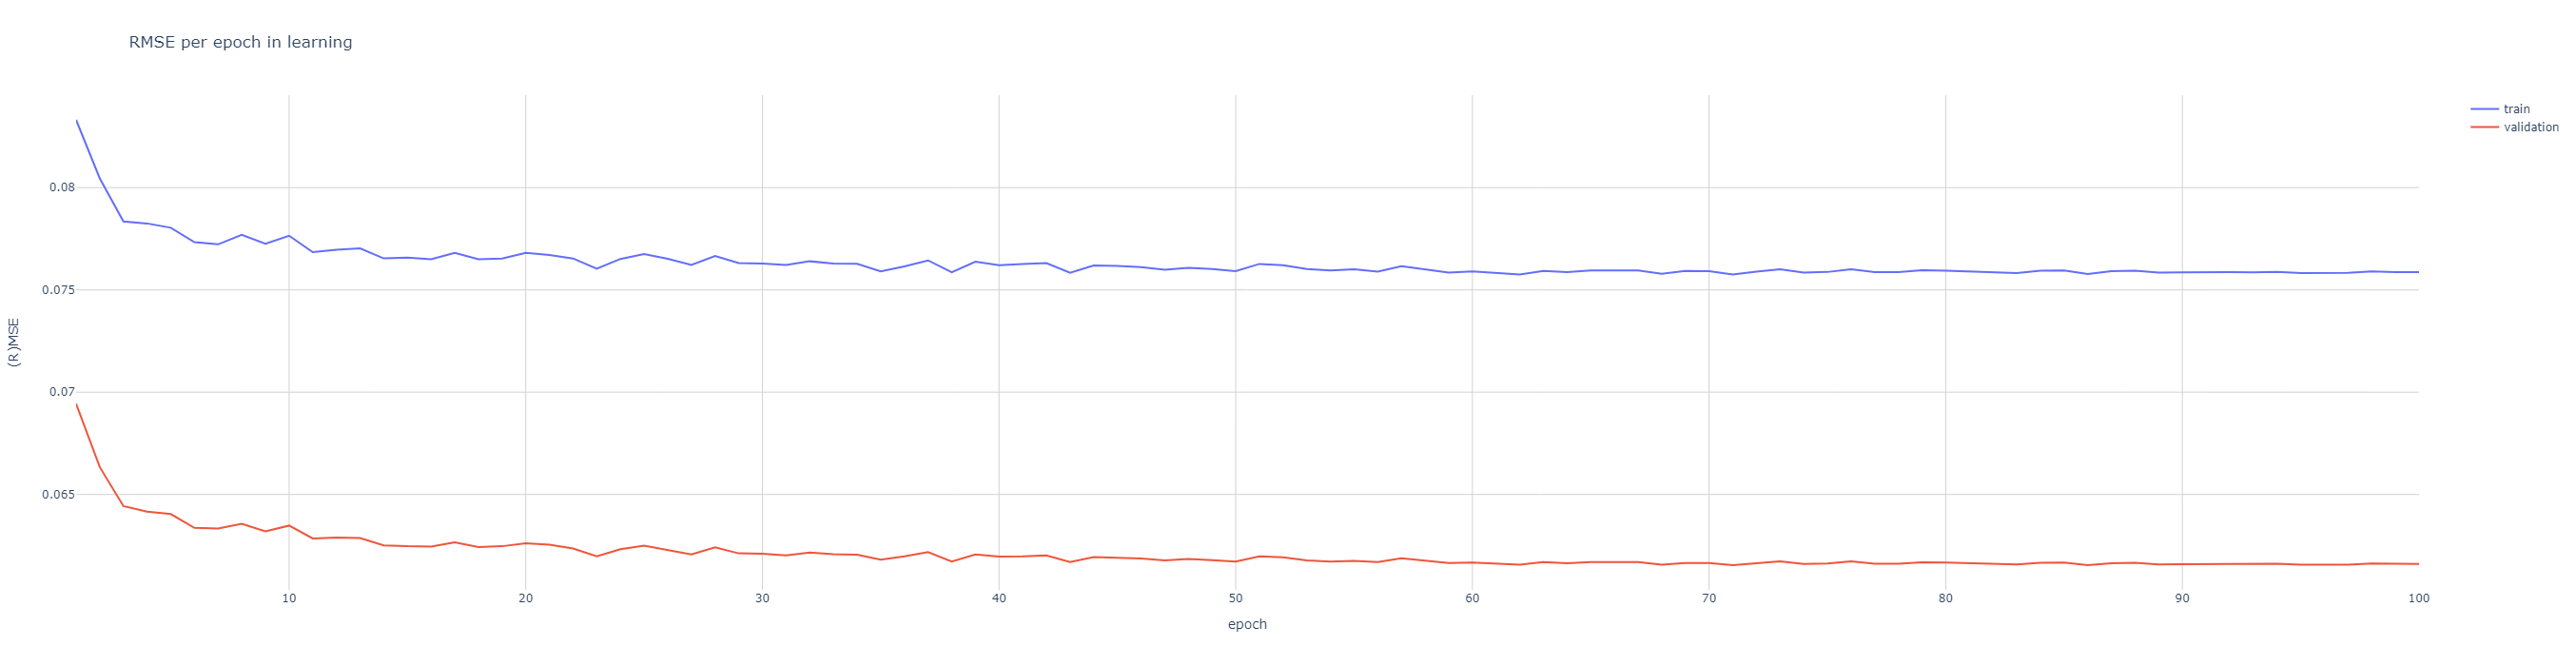

In [44]:
epoch_list = np.arange(1, len(train_list)+1)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=epoch_list,
    y=train_list,
    name="train"
))


fig.add_trace(go.Scatter(
    x=epoch_list,
    y=val_list,
    name="validation"
))

fig.update_layout(
    title="RMSE per epoch in learning",
    xaxis_title="epoch",
    yaxis_title="RMSE",
     xaxis = dict(
        title = 'epoch',
        gridcolor='lightgrey'),
    yaxis = dict(
        title = '(R)MSE',
        gridcolor='lightgrey'), 
    paper_bgcolor='rgba(0,0,0,0)',
    plot_bgcolor='rgba(0,0,0,0)',
    width=1000,
    height=700
)

fig.show()

In [45]:
y_pred, y_target, scenarios = div.plotter(model, test_dataset)

y_pred2 = scale_y.inverse_transform(np.array(y_pred).reshape(-1, 2))
y_target2 = scale_y.inverse_transform(np.array(y_target).reshape(-1, 2))

df_results = test_df.copy()


df_results[["Dispatch_cost_target", "Correction_cost_target"]] = y_target2
df_results[["Dispatch_cost_pred", "Correction_cost_pred"]] = y_pred2
#df_results['tot_cost_pred'] = df_results["Dispatch_cost_pred"] + df_results["Correction_cost_pred"]

In [46]:
# Add regression results on dataframe with classification results
df_classification_results = test_df_classifiction
df_classification_results['pred_f2'] = y_pred_f2

y_pred_c, _, _ = div.plotter(model, classification_test_dataset)

y_pred2_c = scale_y.inverse_transform(np.array(y_pred_c).reshape(-1, 2))

df_classification_results[["Dispatch_cost_pred", "Correction_cost_pred"]] = y_pred2_c

#df_classification_results['tot_cost_pred'] = df_classification_results["Dispatch_cost_pred"] + df_classification_results["Correction_cost_pred"]
#y_pred, y_target, scenarios = div.plotter(model, test_dataset)

In [47]:
df_classification_results.columns

Index(['prev_id', 'Line10', 'Line11', 'Line18', 'Line19', 'Area1_prod',
       'Area2_prod', 'Area3_prod', 'Area1_load', 'Area2_load', 'Area3_load',
       'inter_area_flow', 'fault', 'corr', 'Dispatch costs', 'CENS',
       'FCR cost', 'Redispatch cost', 'SPS cost', 'Correction cost',
       'Total cost', 'Area1-corr', 'Area2-corr', 'Area3-corr', 'Area1-fault',
       'Area2-fault', 'Area3-fault', 'Area1-fault2', 'Area2-fault2',
       'Area3-fault2', 'Class', 'inter_area_flow_scaled', 'Area1_prod_scaled',
       'Area2_prod_scaled', 'Area3_prod_scaled', 'pred_f2',
       'Dispatch_cost_pred', 'Correction_cost_pred'],
      dtype='object')

Dispatch cost rmse: 0.00015525285499141925
Corrective cost rmse: 0.0035905466096428167


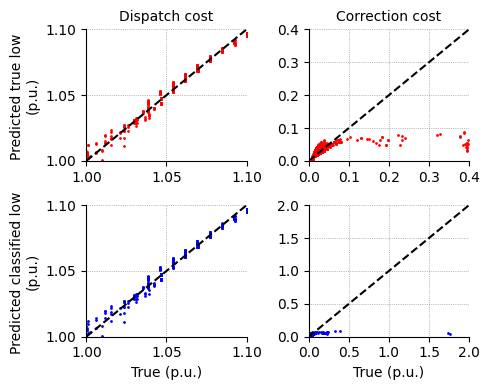

In [48]:
from matplotlib import ticker


thresh = class_thresh
plot_dfl = df_results
fig, ax = plt.subplots(2, 2, figsize=(5, 4))
plt.subplots_adjust(wspace = 0.4, hspace = 0.3)


x = plot_dfl['Dispatch_cost_target']
y = plot_dfl['Dispatch_cost_pred']
rmse = np.sqrt(np.sum((x-y)**2))/len(x)
print('Dispatch cost rmse:', rmse)
ax[0,0].scatter(x, y, color = 'red', s=1)
ax[0,0].xaxis.set_major_locator(ticker.MultipleLocator(0.05))
ax[0,0].yaxis.set_major_locator(ticker.MultipleLocator(0.05))
ax[0,0].plot([1, 1.1], [1, 1.1], ls="--", color='black')
ax[0,0].set_xlim(1, 1.1)
ax[0,0].set_ylim(1, 1.1)
ax[0,0].set_title('Dispatch cost', fontsize=10)


x = plot_dfl['Correction_cost_target']
y = plot_dfl['Correction_cost_pred']
rmse = np.sqrt(np.sum((x-y)**2))/len(x)
print('Corrective cost rmse:', rmse)
ax[0,1].scatter(x, y, color='red', s=1)
ax[0,1].plot([0, 0.4], [0, 0.4], ls="--", color='black')
ax[0,1].xaxis.set_major_locator(ticker.MultipleLocator(0.1))
ax[0,1].yaxis.set_major_locator(ticker.MultipleLocator(0.1))
ax[0,1].set_xlim(0, 0.4)
ax[0,1].set_ylim(0, 0.4)
ax[0,1].set_title('Correction cost', fontsize=10)

index_lowcost = df_classification_results['pred_f2'] == 0
x = df_classification_results.loc[index_lowcost, 'Dispatch costs']
y = df_classification_results.loc[index_lowcost, 'Dispatch_cost_pred']
ax[1,0].scatter(x, y, color='blue', s=1)
ax[1,0].xaxis.set_major_locator(ticker.MultipleLocator(0.05))
ax[1,0].yaxis.set_major_locator(ticker.MultipleLocator(0.05))
ax[1,0].plot([1, 1.1], [1, 1.1], ls="--", color='black')
ax[1,0].set_xlim(1, 1.1)
ax[1,0].set_ylim(1, 1.1)

x = df_classification_results.loc[index_lowcost, 'Correction cost']
y = df_classification_results.loc[index_lowcost, 'Correction_cost_pred']
ax[1,1].scatter(x, y, color='blue', s=1)
ax[1,1].plot([0, 2], [0, 2], ls="--", color='black')
ax[1,1].xaxis.set_major_locator(ticker.MultipleLocator(0.5))
ax[1,1].yaxis.set_major_locator(ticker.MultipleLocator(0.5))
ax[1,1].set_xlim(0, 2)
ax[1,1].set_ylim(0, 2)

ax[1,0].set_xlabel("True (p.u.)")
ax[1,1].set_xlabel("True (p.u.)")

ax[0,0].set_ylabel("Predicted true low \n(p.u.)")
ax[1,0].set_ylabel("Predicted classified low \n(p.u.)")


ax[0,0].spines['right'].set_visible(False)
ax[0,1].spines['right'].set_visible(False)
ax[1,0].spines['right'].set_visible(False)
ax[1,1].spines['right'].set_visible(False)

ax[0,0].spines['top'].set_visible(False)
ax[0,1].spines['top'].set_visible(False)
ax[1,0].spines['top'].set_visible(False)
ax[1,1].spines['top'].set_visible(False)

ax[0,0].grid(linestyle=':', linewidth='0.5', color='grey')
ax[0,1].grid(linestyle=':', linewidth='0.5', color='grey')
ax[1,0].grid(linestyle=':', linewidth='0.5', color='grey')
ax[1,1].grid(linestyle=':', linewidth='0.5', color='grey')
plt.tight_layout()
plt.savefig("./paper_figs/true_vs_pred_new.pdf")
plt.show()

In [49]:
# Only look at instances already classified as low cost
index_lowcost = df_classification_results['pred_f2'] == 0

# Include all corrective for preventive with one low-cost corrective
df_rl = df_classification_results.copy()
df_rl.loc[~index_lowcost, 'Correction_cost_pred'] = high_cost_corrective  # class_thresh # - df_rl.loc[~index_lowcost, 'Dispatch_cost_pred']


In [50]:
#Keep lowest cost per given prv and fault
df_rl["prev_id, fault"] = df_rl[['prev_id', 'fault']].agg('-'.join, axis=1)

# To make plot for low cost and set max_ to be threshold value

# First find out how many failure scenarios per prev has in dataset

agg = {
    'fault': list,
    'corr': list,
}

df_fault = df_rl.groupby("prev_id").agg(agg)
df_fault["fault unique"] = df_fault["fault"].apply(lambda row: list(dict.fromkeys(row)))
df_fault.head()

,fault,corr,fault unique
prev_id,,,
p1000,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1035,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1041,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1042,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"
p1050,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]","[fault_L10, fault_L11, fault_L18, fault_L19]"


In [51]:
# Derive the number of faults classified as high cost for each preventive id (denoted by missing)

df_fault["num fault missing"] = df_fault["fault unique"].apply(lambda row: 4 - len(row))
df_fault[df_fault["num fault missing"] != 0].head()
print(len(df_fault[df_fault["num fault missing"] != 0]))

0


In [52]:
df_rl.set_index('prev_id', inplace=True)

# Add to dataframe
df_rl = df_rl.join(df_fault[['num fault missing']])

In [53]:
# Sort values in ascending order so value kept is corrective measure with lowest cost
df_sort = df_rl.sort_values(['prev_id, fault', 'Total cost'])
df_d = df_sort.drop_duplicates('prev_id, fault', keep='first')
df_d.head()

,Line10,Line11,Line18,Line19,Area1_prod,Area2_prod,Area3_prod,Area1_load,Area2_load,Area3_load,...,Class,inter_area_flow_scaled,Area1_prod_scaled,Area2_prod_scaled,Area3_prod_scaled,pred_f2,Dispatch_cost_pred,Correction_cost_pred,"prev_id, fault",num fault missing
prev_id,,,,,,,,,,,,,,,,,,,,,
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,0.0,0.001624,0.581870,0.425448,0.850175,0,1.070718,0.023914,p1000-fault_L10,0
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,0.0,0.001624,0.581870,0.425448,0.850175,0,1.072047,0.035837,p1000-fault_L11,0
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,0.0,0.001624,0.581870,0.425448,0.850175,0,1.070654,0.022906,p1000-fault_L18,0
p1000,1.349568,111.457467,80.106552,-71.645913,345.740522,252.900003,504.986755,129.41124,102.497107,768.196686,...,0.0,0.001624,0.581870,0.425448,0.850175,0,1.068389,0.022307,p1000-fault_L19,0
p1035,43.065264,131.722460,70.927479,-63.584629,407.721211,193.943950,501.962118,129.41124,102.497107,768.196686,...,0.0,0.071908,0.686298,0.326116,0.845079,0,1.056937,0.037863,p1035-fault_L10,0


In [54]:
# Per scenario: mean dispatch cost and sum correction costs

aggregations = {
    'inter_area_flow': 'mean',
    'Line11': 'mean',
    'Line10': 'mean',
    'fault': list,
    'corr': list,
    'Dispatch costs': 'mean', # Mean of dispatch costs
    'Dispatch_cost_pred': 'mean',
    'Correction cost': 'sum', # Sum up correction costs
    'Correction_cost_pred': 'sum',
    'CENS': 'mean',
    'num fault missing': 'mean'
}

# Use formula given earlier to find cost per preventive strategy

df_prev = df_d.groupby("prev_id").agg(aggregations)
df_prev.head()

,inter_area_flow,Line11,Line10,fault,corr,Dispatch costs,Dispatch_cost_pred,Correction cost,Correction_cost_pred,CENS,num fault missing
prev_id,,,,,,,,,,,
p1000,1.349568,111.457467,1.349568,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.069159,1.070452,0.109234,0.104963,0.0,0.0
p1035,43.065264,131.722460,43.065264,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.053963,1.057188,0.123169,0.145326,0.0,0.0
p1041,18.548246,111.457467,18.548246,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.069270,1.071635,0.099762,0.106419,0.0,0.0
p1042,37.533339,111.457467,37.533339,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.069392,1.068892,0.089178,0.114332,0.0,0.0
p1050,0.385843,81.059977,0.385843,"[fault_L10, fault_L11, fault_L18, fault_L19]","[fault, fault, fault, fault]",1.092439,1.089774,0.062704,0.063856,0.0,0.0


In [55]:
df_states = pd.read_csv(r'./data/state_prev_300322.csv')
for prev_id in df_prev.index:
    df_prev.loc[prev_id, 'state'] = df_states[df_states['Unnamed: 0'] == prev_id].state.values

In [56]:
# Find prev ids that have one or more scenarios with CENS or saved by SPS

#df_prev["corr_unique"] = df_prev["corr"].apply(lambda x: list(dict.fromkeys(x)))

In [57]:
#def classify_prev(row):
#    if row["CENS"] > 0:
#        return "Not N-1 safe"
#    else:
#        if len(row["corr_unique"])==1 and row["corr_unique"][0] == 'fault':
#            return "N-1 safe"
#        else:
#            return "Saved by SPS"
#df_prev["corr3"] = df_prev.apply(classify_prev, axis=1)  
#df_prev[df_prev["corr3"] != "N-1 safe"]

In [58]:
#Calculate total expected cost given failure_rate
failure_rate = 0.01
df_prev["total_cost_target"] =  df_prev["Dispatch costs"] + failure_rate*df_prev["Correction cost"]
df_prev["total_cost_pred"] =  df_prev["Dispatch_cost_pred"] + failure_rate*df_prev["Correction_cost_pred"]

In [59]:
df_prev["total_cost_target"].max()

1.378178419362932

In [60]:
aggregations = {
    'inter_area_flow': 'mean',
    'Line11': 'mean',
    'Line10': 'mean',

    'fault': list,
    'corr': list,
    'Dispatch costs': 'mean', # Mean of dispatch costs
    'Dispatch_cost_pred': 'mean',
    'Correction cost': 'sum', # Sum up correction costs
    'Correction_cost_pred': 'sum',
    'CENS': 'mean',
}


df_prev_classification = df_classification_results.groupby("prev_id").agg(aggregations)
for prev_id in df_prev_classification.index:
    df_prev_classification.loc[prev_id, 'state'] = df_states[df_states['Unnamed: 0'] == prev_id].state.values
    
df_prev_classification["total_cost_target"] =  df_prev_classification["Dispatch costs"] + failure_rate*df_prev_classification["Correction cost"]

In [61]:
plot_df = df_prev.copy(deep=True)
groups = ["N-1 safe", "Saved by SPS", "Not N-1 safe"]
colors = ["#1F77B4","#FFDA00", "#FF6600"]
symbols = ["o", "s", "^"]

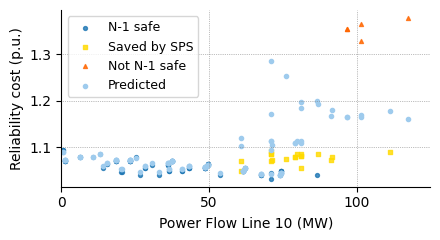

In [62]:
fig, ax = plt.subplots(figsize=(4.5,2.5))

for cnt in range(0,3):
    group=groups[cnt]
    ax.scatter(plot_df.loc[plot_df['state']==group]["Line10"], plot_df.loc[plot_df['state']==group]["total_cost_target"],
                color=colors[cnt],
                marker=symbols[cnt],
                s=8,
                alpha=0.8,
                label=group,)
ax.scatter(plot_df["Line10"], plot_df['total_cost_pred'],
           marker="o", color='#9ecbed', s=9, label="Predicted")
    
    
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.grid(linestyle=':', linewidth='0.5', color='grey')
ax.set_ylabel('Reliability cost (p.u.)', fontsize=10)
ax.set_xlabel('Power Flow Line 10 (MW)', fontsize=10)
ax.set_xlim(left=0)
ax.xaxis.set_major_locator(ticker.MultipleLocator(50))
plt.tight_layout()
plt.legend(fontsize=9)
plt.savefig("./paper_figs/Line10_new.pdf")
plt.show()

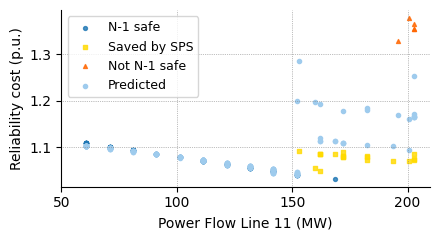

In [63]:
fig, ax = plt.subplots(figsize=(4.5,2.5))

for cnt in range(0,3):
    group=groups[cnt]
    ax.scatter(plot_df.loc[plot_df['state']==group]["Line11"], plot_df.loc[plot_df['state']==group]["total_cost_target"],
                color=colors[cnt],
                marker=symbols[cnt],
                s=8,
                alpha=0.8,
                label=group,)
ax.scatter(plot_df["Line11"], plot_df['total_cost_pred'],
           marker="o", color='#9ecbed', s=9, label="Predicted")
    
    
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.grid(linestyle=':', linewidth='0.5', color='grey')
ax.set_ylabel('Reliability cost (p.u.)', fontsize=10)
ax.set_xlabel('Power Flow Line 11 (MW)', fontsize=10)
ax.set_xlim(left=50)
ax.xaxis.set_major_locator(ticker.MultipleLocator(50))
plt.tight_layout()
plt.legend(fontsize=9)
plt.savefig("./paper_figs/Line11_new.pdf")
plt.show()

In [ ]:
#plot_df['total_cost_pred'].max()

In [ ]:
df_classification_results